# Predicting Final Exam Marks with Linear Regression

Predict a student's final exam mark from their earlier marks, and understand the maths behind linear regression step by step.

**Contents**
1. Problem statement
2. Dataset
3. Loading the data
4. Checking the data
5. Exploratory data analysis (EDA)
6. Approach: the maths of linear regression
7. Train / test split
8. Simple linear regression (2nd-term mark → final mark)
9. Gradient descent
10. Multiple linear regression (more columns)
11. Evaluation: MAE, RMSE and R²
12. Leakage awareness
13. Predict a student's final mark
14. Conclusion

## 1. Problem Statement

A teacher knows each student's marks from the first two terms. Before the final exam, they want to spot the students who are heading for a low final mark, so they can help them in time. For that we need to **predict the final mark**.

**Task:** predict a student's final mark (out of 20) from the information available before the final exam.

| | |
|---|---|
| **Type of problem** | Supervised learning, **regression** (the answer is a number) |
| **Input (X)** | 2nd-term mark; later also 1st-term mark, weekly study time, past failures and absences |
| **Output (y)** | Final mark, from 0 to 20 |
| **Model** | Linear regression |
| **How we measure success** | MAE, RMSE and R² on students the model has never seen |

## 2. Dataset

**Source:** [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance) (UCI Machine Learning Repository, CC BY 4.0), collected by P. Cortez and A. Silva (2008) at two secondary schools in Portugal. We use `student-por.csv`: **649 students** of the Portuguese-language course, one row per student, 33 columns. In Portugal marks are given **out of 20**, and 10 is a pass.

We use 6 of the 33 columns:

| Column | Meaning | Values |
|---|---|---|
| `G1` | 1st-term mark | 0 to 20 |
| `G2` | 2nd-term mark | 0 to 20 |
| `G3` | **final mark** (what we predict) | 0 to 20 |
| `studytime` | weekly study time | 1 = under 2 h, 2 = 2 to 5 h, 3 = 5 to 10 h, 4 = over 10 h |
| `failures` | number of past class failures | 0 to 3 |
| `absences` | number of school absences | 0 to 32 |

## 3. Loading the Data

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# colours and a clean chart style
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True})

DATA_PATH = "/content/drive/MyDrive/workshop/regression/"

raw = pd.read_csv(DATA_PATH + "student-por.csv", sep=";")   # values in this file are separated by ;
print("Rows, columns:", raw.shape)

COLUMNS = ["G1", "G2", "G3", "studytime", "failures", "absences"]
data = raw[COLUMNS]
data.head()

Rows, columns: (649, 33)


,G1,G2,G3,studytime,failures,absences
0,0,11,11,2,0,4
1,9,11,11,2,0,2
2,12,13,12,2,0,6
3,14,14,14,3,0,0
4,11,13,13,2,0,0


## 4. Checking the Data

Before building a model, check that the data can be used as it is: nothing missing, no student twice, and every mark between 0 and 20.

In [ ]:
print("Missing values      :", data.isna().sum().sum())
print("Duplicate students  :", raw.duplicated().sum())
print("Marks from 0 to 20  :", data[["G1", "G2", "G3"]].isin(range(21)).all().all())
data.describe().round(2)

Missing values      : 0
Duplicate students  : 0
Marks from 0 to 20  : True


,G1,G2,G3,studytime,failures,absences
count,649.00,649.00,649.00,649.00,649.00,649.00
mean,11.40,11.57,11.91,1.93,0.22,3.66
std,2.75,2.91,3.23,0.83,0.59,4.64
min,0.00,0.00,0.00,1.00,0.00,0.00
25%,10.00,10.00,10.00,1.00,0.00,0.00
50%,11.00,11.00,12.00,2.00,0.00,2.00
75%,13.00,13.00,14.00,2.00,0.00,6.00
max,19.00,19.00,19.00,4.00,3.00,32.00


The data is **clean**: nothing is missing, no student appears twice, and every mark is a whole number from 0 to 20. No cleaning is needed.

## 5. Exploratory Data Analysis (EDA)

### 5.1 How are the final marks spread?

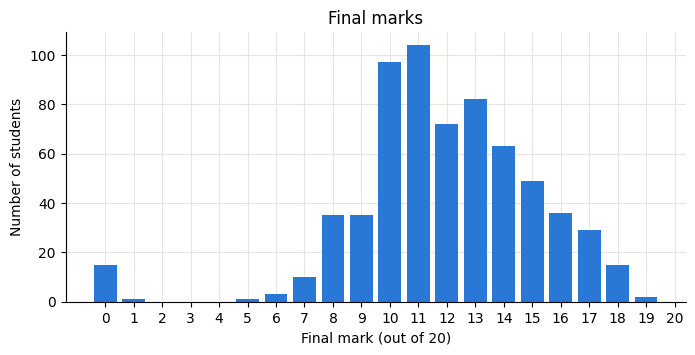

Average final mark: 11.91   Passed (10 or more): 85%
Final mark of 0: 15 students, of whom 7 also had 0 in the 2nd term


In [ ]:
counts = data["G3"].value_counts().sort_index()

plt.figure(figsize=(8, 3.5))
plt.bar(counts.index, counts.values, color=BLUE)
plt.xticks(range(0, 21))
plt.xlabel("Final mark (out of 20)")
plt.ylabel("Number of students")
plt.title("Final marks")
plt.show()

print(f"Average final mark: {data['G3'].mean():.2f}   Passed (10 or more): {(data['G3'] >= 10).mean():.0%}")
print("Final mark of 0:", (data["G3"] == 0).sum(), "students, of whom",
      ((data["G3"] == 0) & (data["G2"] == 0)).sum(), "also had 0 in the 2nd term")

Most students score between 8 and 15, and 85% pass. 15 students have a final mark of **0**: 7 of them already had 0 in the 2nd term, and the other 8 had a normal 2nd-term mark (5 to 9) and then 0 in the final, so most likely they stopped attending the course. They are real students, so we keep them, but no line can see a sudden 0 coming: those 8 will show up later as the biggest errors.

### 5.2 Which columns move with the final mark?
**Correlation** measures how strongly two quantities move together in a straight line: +1 means perfectly together, −1 perfectly opposite, 0 no straight-line relationship.

$$r = \frac{\sum (x - \bar{x})(y - \bar{y})}{\sqrt{\sum (x - \bar{x})^2} \cdot \sqrt{\sum (y - \bar{y})^2}}$$

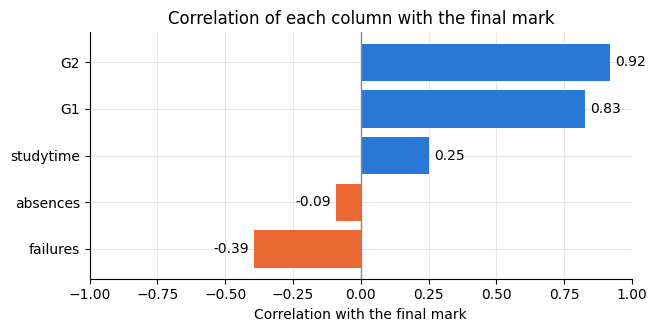

In [ ]:
corr = data.drop(columns="G3").corrwith(data["G3"]).sort_values()

plt.figure(figsize=(7, 3.2))
plt.barh(corr.index, corr.values, color=[ORANGE if v < 0 else BLUE for v in corr.values])
for i, value in enumerate(corr.values):
    plt.text(value + (0.02 if value >= 0 else -0.02), i, f"{value:.2f}", va="center",
             ha="left" if value >= 0 else "right")
plt.xlim(-1, 1)
plt.axvline(0, color=GREY, linewidth=1)
plt.xlabel("Correlation with the final mark")
plt.title("Correlation of each column with the final mark")
plt.show()

The earlier marks are by far the strongest: **2nd-term mark 0.92**, 1st-term mark 0.83. Past failures pull the final mark down (−0.39), study time helps a little (0.25) and absences barely matter (−0.09).

### 5.3 2nd-term mark vs final mark
Marks are whole numbers, so many students share exactly the same point. Each dot is shifted by a small random amount so that overlapping students become visible.

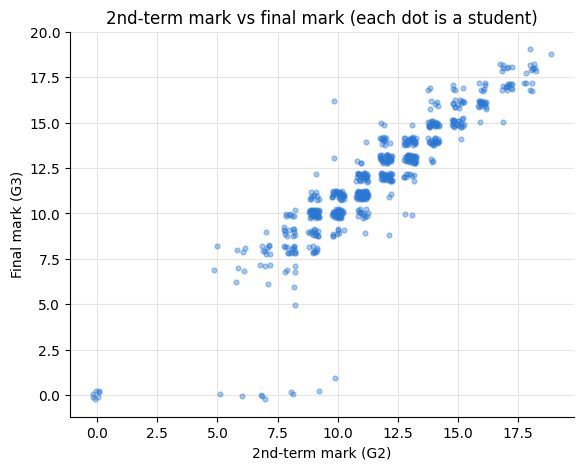

In [ ]:
rng = np.random.default_rng(0)
shift = rng.uniform(-0.25, 0.25, size=(2, len(data)))       # only for the picture

plt.figure(figsize=(6.5, 5))
plt.scatter(data["G2"] + shift[0], data["G3"] + shift[1], s=12, alpha=0.4, color=BLUE)
plt.xlabel("2nd-term mark (G2)")
plt.ylabel("Final mark (G3)")
plt.title("2nd-term mark vs final mark (each dot is a student)")
plt.show()

The dots lie close to a straight rising line: students who did well in the 2nd term usually do well in the final. The dots along the bottom (final mark 0) are the students who stopped attending.

## 6. Approach: the Maths of Linear Regression

**Simple linear regression** (one input $x$) draws a straight line:

$$\hat{y} = m \cdot x + b$$

- $\hat{y}$ ("y-hat") is the **predicted** final mark
- $m$ is the **slope**: how much the prediction rises when $x$ goes up by 1
- $b$ is the **intercept**: the prediction when $x = 0$

**Multiple linear regression** (many inputs) does the same with one slope per input:

$$\hat{y} = b + m_1 x_1 + m_2 x_2 + \dots + m_n x_n$$

**How the best line is chosen:** the **error** (or **residual**) of one student is $y - \hat{y}$. Linear regression picks the $m$ and $b$ with the smallest **mean squared error (MSE)**:

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Squaring makes every error positive and makes big errors count more.

**Plan:** split the data → fit a line with one column (2nd-term mark) → see how gradient descent finds it → use more columns → measure the errors on unseen students.

## 7. Train / Test Split

We hide 20% of the students as a **test set**. The model learns from the other 80% (**training set**), and the test set tells us how well it works on students it has never seen.

We shuffle the row numbers first so the split is random, and fix the random seed so we get the same split every time.

In [ ]:
rng = np.random.default_rng(42)              # seed 42 -> same shuffle every run
shuffled = rng.permutation(len(data))        # row numbers in random order
n_test = int(0.2 * len(data))                # 20% of the students

test_rows, train_rows = shuffled[:n_test], shuffled[n_test:]
train, test = data.iloc[train_rows], data.iloc[test_rows]
print("Training students:", len(train), "   Test students:", len(test))

Training students: 520    Test students: 129


## 8. Simple Linear Regression: 2nd-Term Mark → Final Mark

### 8.1 Starting point: always guess the average
The simplest "model" predicts the **average final mark** $\bar{y}$ for every student. Its MSE is the number every real model must beat.

In [ ]:
x = train["G2"].to_numpy()       # input: 2nd-term mark
y = train["G3"].to_numpy()       # target: final mark

errors = y - y.mean()
mse_mean = np.mean(errors ** 2)

print(f"Average final mark ȳ : {y.mean():.2f}")
print(f"MSE when guessing ȳ  : {mse_mean:.2f}  (marks², because errors are squared)")
print(f"RMSE = √MSE          : {np.sqrt(mse_mean):.2f}  (back in marks)")

Average final mark ȳ : 11.90
MSE when guessing ȳ  : 10.12  (marks², because errors are squared)
RMSE = √MSE          : 3.18  (back in marks)


### 8.2 The best line, using the formula
Minimising the MSE with calculus gives a direct formula for the best slope and intercept:

$$m = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2} \qquad\qquad b = \bar{y} - m \cdot \bar{x}$$

Let's compute it by hand with NumPy, and then check it against scikit-learn's `LinearRegression`.

In [ ]:
m = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b = y.mean() - m * x.mean()
print(f"By formula          : final = {m:.3f} × G2 + ({b:.3f})")

simple = LinearRegression()
simple.fit(train[["G2"]], train["G3"])
print(f"By LinearRegression : final = {simple.coef_[0]:.3f} × G2 + ({simple.intercept_:.3f})")

By formula          : final = 1.008 × G2 + (0.232)
By LinearRegression : final = 1.008 × G2 + (0.232)


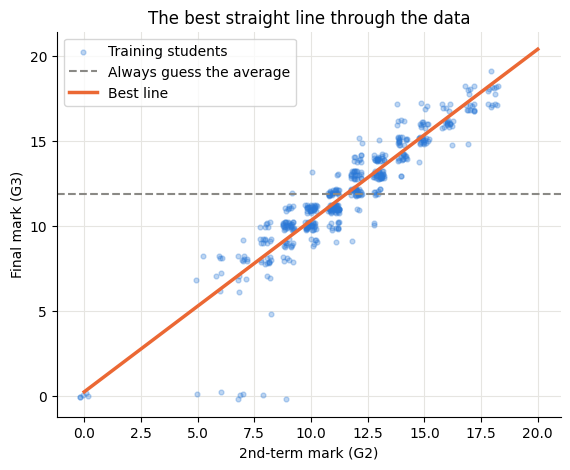

In [ ]:
line_x = np.linspace(0, 20, 100)

plt.figure(figsize=(6.5, 5))
plt.scatter(x + rng.uniform(-0.25, 0.25, len(x)), y + rng.uniform(-0.25, 0.25, len(y)),
            s=12, alpha=0.3, color=BLUE, label="Training students")
plt.axhline(y.mean(), color=GREY, linestyle="--", label="Always guess the average")
plt.plot(line_x, m * line_x + b, color=ORANGE, linewidth=2.5, label="Best line")
plt.xlabel("2nd-term mark (G2)")
plt.ylabel("Final mark (G3)")
plt.title("The best straight line through the data")
plt.legend()
plt.show()

**Reading the line:** every extra mark in the 2nd term adds about 1.008 marks to the predicted final mark, and the intercept is close to 0 (0.232). So, roughly, **final mark ≈ 2nd-term mark + 0.3**: the final exam mostly confirms what the 2nd term already showed.

### 8.3 Predictions and residuals
To predict, put the 2nd-term mark into the equation. The **residual** is what the line gets wrong:

$$\text{residual} = y - \hat{y} = \text{actual final mark} - \text{predicted final mark}$$

In [ ]:
for g2 in [8, 12, 16]:
    print(f"G2 = {g2:2d} -> predicted final mark = {m:.3f} × {g2} + ({b:.3f}) = {m * g2 + b:.2f}")

residuals = y - (m * x + b)
print(f"\nSum of all residuals: {residuals.sum():.2f}")

G2 =  8 -> predicted final mark = 1.008 × 8 + (0.232) = 8.29
G2 = 12 -> predicted final mark = 1.008 × 12 + (0.232) = 12.33
G2 = 16 -> predicted final mark = 1.008 × 16 + (0.232) = 16.36

Sum of all residuals: 0.00


The residuals add up to **zero** (apart from tiny rounding). This is always true for the least-squares line: it passes through the "centre" $(\bar{x}, \bar{y})$ of the data, so the errors above and below the line cancel out.

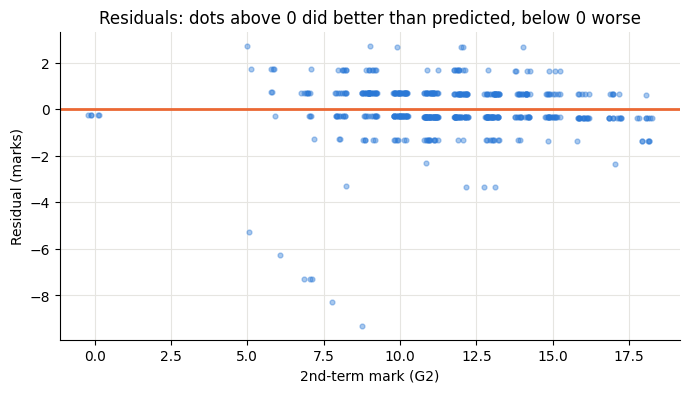

Within 1 mark of the line : 81% of the students
Within 2 marks of the line: 96% of the students
Biggest misses: [-9.3 -8.3 -7.3]  (students whose final mark was 0)


In [ ]:
plt.figure(figsize=(8, 4))
plt.scatter(x + rng.uniform(-0.25, 0.25, len(x)), residuals, s=12, alpha=0.4, color=BLUE)
plt.axhline(0, color=ORANGE, linewidth=2)
plt.xlabel("2nd-term mark (G2)")
plt.ylabel("Residual (marks)")
plt.title("Residuals: dots above 0 did better than predicted, below 0 worse")
plt.show()

print(f"Within 1 mark of the line : {np.mean(np.abs(residuals) <= 1):.0%} of the students")
print(f"Within 2 marks of the line: {np.mean(np.abs(residuals) <= 2):.0%} of the students")
print(f"Biggest misses: {np.sort(residuals)[:3].round(1)}  (students whose final mark was 0)")

81% of the students are within 1 mark of the line and 96% within 2 marks. The few dots far below are the students with a final mark of 0: the line predicted a normal mark from their 2nd term, but their final mark was 0.

### 8.4 Why this line? Looking at the loss
Let's try many different slopes and compute the MSE of each (each time with the best intercept $b = \bar{y} - m\bar{x}$).

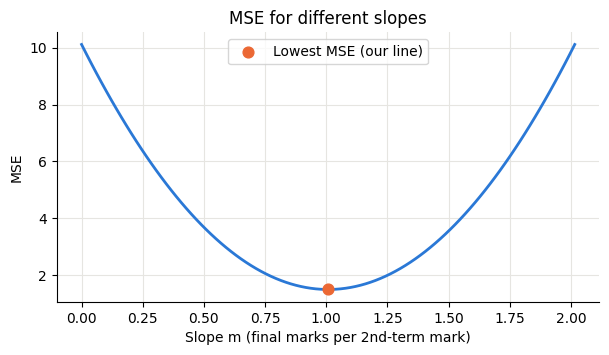

In [ ]:
slopes = np.linspace(0, 2 * m, 100)
losses = [np.mean((y - (s * x + (y.mean() - s * x.mean()))) ** 2) for s in slopes]

plt.figure(figsize=(7, 3.5))
plt.plot(slopes, losses, color=BLUE, linewidth=2)
plt.scatter([m], [np.mean(residuals ** 2)], color=ORANGE, s=60, zorder=3, label="Lowest MSE (our line)")
plt.xlabel("Slope m (final marks per 2nd-term mark)")
plt.ylabel("MSE")
plt.title("MSE for different slopes")
plt.legend()
plt.show()

The MSE forms a **bowl** (a parabola): too flat or too steep both give bigger errors, and there is one lowest point, which is exactly the slope from our formula. The formula jumps straight to the bottom. **Gradient descent** walks down to it step by step.

## 9. Gradient Descent

Gradient descent finds the bottom of the bowl by repeatedly stepping downhill:

1. Start with any line, e.g. $m = 0, b = 0$.
2. Compute the **gradient** (the slope of the bowl) for $m$ and $b$:

$$\frac{\partial \text{MSE}}{\partial m} = -\frac{2}{n}\sum x_i (y_i - \hat{y}_i) \qquad \frac{\partial \text{MSE}}{\partial b} = -\frac{2}{n}\sum (y_i - \hat{y}_i)$$

3. Step in the opposite direction: $\; m \leftarrow m - \alpha \cdot \frac{\partial \text{MSE}}{\partial m}, \quad b \leftarrow b - \alpha \cdot \frac{\partial \text{MSE}}{\partial b}$
4. Repeat.

$\alpha$ is the **learning rate**: the size of each step.

The 2nd-term mark is around 11 on average, far from 0, so a change in $m$ moves the line much more than the same change in $b$. We first **scale** the mark to $z = (x - \bar{x}) / \sigma$ (mean 0, spread 1), so $m$ and $b$ learn at a similar speed. At the end we convert back to "final marks per 2nd-term mark".

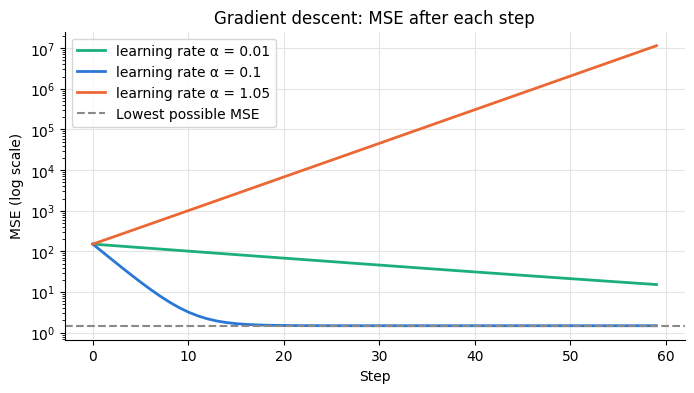

In [ ]:
z = (x - x.mean()) / x.std()           # scaled 2nd-term mark

def gradient_descent(learning_rate, steps):
    m_z, b_z = 0.0, 0.0                 # start with a flat line at 0
    losses = []
    for _ in range(steps):
        y_hat = m_z * z + b_z
        losses.append(np.mean((y - y_hat) ** 2))
        grad_m = -2 * np.mean(z * (y - y_hat))
        grad_b = -2 * np.mean(y - y_hat)
        m_z = m_z - learning_rate * grad_m
        b_z = b_z - learning_rate * grad_b
    return m_z, b_z, losses

plt.figure(figsize=(8, 4))
for lr, colour in [(0.01, GREEN), (0.1, BLUE), (1.05, ORANGE)]:
    _, _, losses = gradient_descent(lr, 60)
    plt.plot(losses, color=colour, linewidth=2, label=f"learning rate α = {lr}")
plt.axhline(np.mean(residuals ** 2), color=GREY, linestyle="--", label="Lowest possible MSE")
plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("MSE (log scale)")
plt.title("Gradient descent: MSE after each step")
plt.legend()
plt.show()

- **α = 0.1** reaches the lowest MSE in about 20 steps.
- **α = 0.01** goes the right way, but very slowly.
- **α = 1.05** takes steps that are too big: it jumps over the bottom of the bowl and the error **grows**.

Now we run it with α = 0.1 and convert the result back:

In [ ]:
m_z, b_z, losses = gradient_descent(0.1, 200)
m_gd = m_z / x.std()                    # slope per 2nd-term mark
b_gd = b_z - m_gd * x.mean()            # intercept

print(f"Gradient descent : final = {m_gd:.3f} × G2 + ({b_gd:.3f})")
print(f"Formula          : final = {m:.3f} × G2 + ({b:.3f})")

Gradient descent : final = 1.008 × G2 + (0.232)
Formula          : final = 1.008 × G2 + (0.232)


Both methods give the **same line**. Linear regression has a direct formula, but most other models (for example neural networks) do not, and they are trained with gradient descent.

## 10. Multiple Linear Regression: More Columns

Now we use five columns together:

$$\widehat{\text{final}} = b + m_1 \cdot \text{G2} + m_2 \cdot \text{G1} + m_3 \cdot \text{studytime} + m_4 \cdot \text{failures} + m_5 \cdot \text{absences}$$

**The formula for many columns.** Put the inputs in a table $X$ with an extra column of 1s (for the intercept) and collect $b, m_1, \dots, m_5$ in one list $\beta$. Minimising the MSE then gives the **normal equation**:

$$\beta = (X^\top X)^{-1} X^\top y$$

With one column this is exactly the slope and intercept formula from Section 8.2. Let's compute it by hand and check it against scikit-learn.

In [ ]:
FEATURES = ["G2", "G1", "studytime", "failures", "absences"]

X_train, X_test = train[FEATURES].to_numpy(), test[FEATURES].to_numpy()
y_train, y_test = train["G3"].to_numpy(), test["G3"].to_numpy()

A = np.column_stack([np.ones(len(X_train)), X_train])      # column of 1s -> intercept
beta = np.linalg.inv(A.T @ A) @ A.T @ y_train

model = LinearRegression()
model.fit(X_train, y_train)

print("                 intercept " + " ".join(f"{name:>9s}" for name in FEATURES))
print("Normal equation:", " ".join(f"{v:9.3f}" for v in beta))
print("LinearRegression", " ".join(f"{v:9.3f}" for v in np.r_[model.intercept_, model.coef_]))

                 intercept        G2        G1 studytime  failures  absences
Normal equation:    -0.106     0.902     0.115     0.103    -0.155     0.024
LinearRegression    -0.106     0.902     0.115     0.103    -0.155     0.024


**How to read the numbers:** each slope is the change in the predicted final mark for +1 of that column **when all other columns stay the same**.

- **2nd-term mark (G2)** matters by far the most: +0.902 per mark.
- **1st-term mark (G1)** adds a little extra (+0.115).
- **Study time** helps a little: +0.103 per step (for example from "2 to 5 h" to "5 to 10 h" a week).
- **Past failures** pull the mark down: −0.155 per failure.
- **Absences** change almost nothing (+0.024 per absence) once the earlier marks are known.

## 11. Evaluation: MAE, RMSE and R²

We measure the errors on the **test set**, which the models have never seen. With $n$ students, actual final marks $y_i$ and predictions $\hat{y}_i$:

$$\text{MAE} = \frac{1}{n}\sum |y_i - \hat{y}_i| \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2} \qquad R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

- **MAE**: the average error, in marks.
- **RMSE**: like MAE, but big errors count more (RMSE ≥ MAE).
- **R²**: the share of the differences between students that the model explains. 1 = perfect, 0 = no better than guessing the average.

In [ ]:
def evaluate(actual, predicted):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    r2 = 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)
    return mae, rmse, r2

predictions = {
    "Guess the average": np.full(len(y_test), y_train.mean()),
    "Simple: G2 only": simple.predict(test[["G2"]]),
    "Multiple: 5 columns": model.predict(X_test),
}
for name, pred in predictions.items():
    mae, rmse, r2 = evaluate(y_test, pred)
    print(f"{name:20s}  MAE {mae:5.2f}   RMSE {rmse:5.2f}   R² {r2:6.3f}")

Guess the average     MAE  2.58   RMSE  3.41   R² -0.000
Simple: G2 only       MAE  0.88   RMSE  1.48   R²  0.811
Multiple: 5 columns   MAE  0.85   RMSE  1.44   R²  0.822


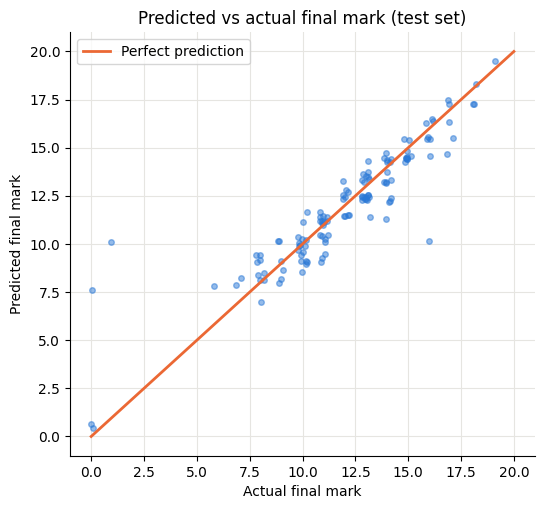

In [ ]:
pred = model.predict(X_test)

plt.figure(figsize=(6, 5.5))
plt.scatter(y_test + rng.uniform(-0.2, 0.2, len(y_test)), pred, s=16, alpha=0.5, color=BLUE)
plt.plot([0, 20], [0, 20], color=ORANGE, linewidth=2, label="Perfect prediction")
plt.xlabel("Actual final mark")
plt.ylabel("Predicted final mark")
plt.title("Predicted vs actual final mark (test set)")
plt.legend()
plt.show()

- Guessing the average is off by 2.58 marks on average. The 2nd-term mark alone cuts that to **0.88 marks** and explains about **81%** of the differences between students (R² 0.811).
- Adding four more columns helps only a little (MAE 0.85, R² 0.822): almost everything they know is already in the 2nd-term mark. **More columns do not automatically make a better model.**
- Most dots sit close to the orange line: only 3 of the 129 test students are off by more than 3 marks. Two of them scored 0 or 1 in the final after a normal 2nd term; the third jumped from 10 in the 2nd term to 16 in the final.

## 12. Leakage Awareness

**Data leakage** happens when the model is trained with information it would **not have when making a real prediction**. The score looks great, but the model is useless in practice.

**Example:** the report card also shows each student's **year average**, the mean of the three marks. Suppose we added that column as an input. We **simulate** it here:

In [ ]:
year_average_train = (train["G1"] + train["G2"] + train["G3"]) / 3
year_average_test = (test["G1"] + test["G2"] + test["G3"]) / 3

leaky_train = np.column_stack([X_train, year_average_train])
leaky_test = np.column_stack([X_test, year_average_test])

leaky_model = LinearRegression().fit(leaky_train, y_train)
print(f"R² without year average: {evaluate(y_test, model.predict(X_test))[2]:.3f}")
print(f"R² with year average   : {evaluate(y_test, leaky_model.predict(leaky_test))[2]:.3f}")

R² without year average: 0.822
R² with year average   : 1.000


A **perfect score**, but only because the year average **contains the final mark**: final = 3 × average − G1 − G2. Before the final exam nobody knows the year average, and the final mark is exactly what we want to predict.

**Rule of thumb:** if a score looks too good to be true, check whether a column secretly contains the answer.

## 13. Predict a Student's Final Mark

Change the numbers below and run the cell.

In [ ]:
my_student = {"G2": 13, "G1": 12, "studytime": 2, "failures": 0, "absences": 4}

row = np.array([[my_student[name] for name in FEATURES]])
print(f"Predicted final mark: {model.predict(row)[0]:.1f} out of 20")

Predicted final mark: 13.3 out of 20


## 14. Conclusion

| Model (test set) | MAE | RMSE | R² |
|---|---|---|---|
| Guess the average | 2.58 | 3.41 | −0.00 |
| Simple: 2nd-term mark only | 0.88 | 1.48 | 0.81 |
| **Multiple: 5 columns** | **0.85** | **1.44** | **0.82** |

- The data was already clean: 649 students, nothing missing, every mark from 0 to 20.
- The **least-squares formula**, **gradient descent** and the **normal equation** all gave exactly the same answer as scikit-learn.
- The 2nd-term mark alone explains about 81% of the differences in final marks: roughly, final mark ≈ 2nd-term mark + 0.3.
- Four more columns improved the result only slightly. More columns do not automatically make a better model.
- The biggest errors are students who scored 0 (or almost 0) in the final after a normal 2nd term: a straight line cannot see that coming.
- A leaky column (the year average) gave a perfect but useless score, which is why every input must be known before the prediction is made.